In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals

sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:
f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/OptimizeSignalStudies/OptimizeSignalStudies.coffea"

sig_histo = util.load(f_sig) [0]
# sig_histo

In [3]:
selected_cut = "cut2"


m1=10, delta=0.2, ctau=100: denominator = 219982
m1=20, delta=0.2, ctau=100: denominator = 285981
m1=30, delta=0.2, ctau=100: denominator = 307204
m1=40, delta=0.2, ctau=100: denominator = 303385
m1=50, delta=0.2, ctau=100: denominator = 275148
m1=60, delta=0.1, ctau=100: denominator = 387820
m1=60, delta=0.2, ctau=100: denominator = 223856
m1=70, delta=0.1, ctau=100: denominator = 378359
m1=70, delta=0.2, ctau=100: denominator = 139727
m1=80, delta=0.1, ctau=100: denominator = 252285
m1=80, delta=0.2, ctau=100: denominator = 163058
m1=90, delta=0.1, ctau=100: denominator = 294517
m1=90, delta=0.2, ctau=100: denominator = 103316
m1=100, delta=0.1, ctau=100: denominator = 249464
m1=100, delta=0.2, ctau=100: denominator = 110862

Cut: cut2
Number of samples: 15
TOTAL denominator = 3.69496e+06


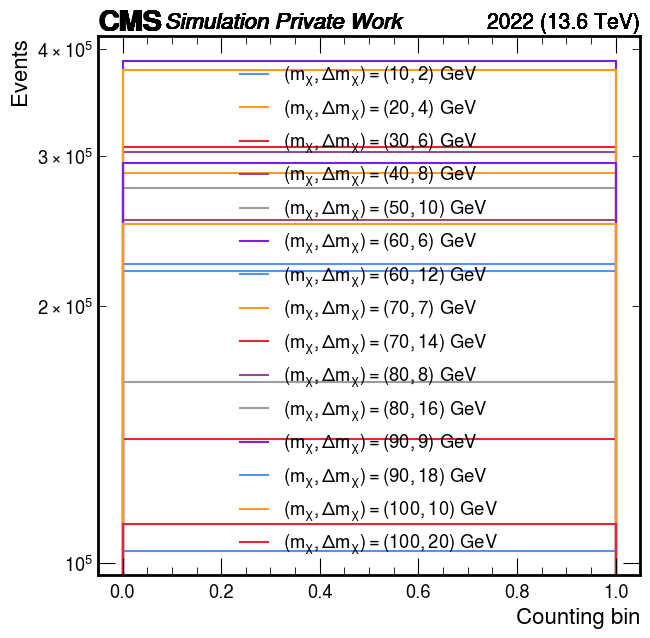

In [4]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'eff_den',
    'cut': selected_cut,
    'year': 2022
}
style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': "Counting bin",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
}

samples = {
    10: 
    {
        
        0.2: [100],
    },
    20: 
    {
        
        0.2: [100],
        
    },
    30: 
    {
       
        0.2: [100]
    },
    40: 
    {
        0.2: [100],
    },
    50:
    {
        
        0.2: [100],
    },
    60:
    {
        
         0.1: [100],
         0.2: [100]
    
    },
    70:
    {    0.1: [100],
         0.2: [100],
    },
    80:
    {    0.1: [100],
         0.2: [100],
    },
    90:
    {    0.1: [100],
         0.2: [100],
    },
    100:
    {    0.1: [100],
         0.2: [100],
    }
 
}



den_counts = {}
total_den = 0.0
den_cut = plot_dict["cut"]

for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            key = (m1, delta, ctau)
            if key in den_counts:
                raise ValueError(f"Sample listed more than once: {key}")
            counts = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            den = float(np.asarray(counts, dtype=float).sum())
            den_counts[key] = den
            total_den += den
            print(f"m1={m1}, delta={delta}, ctau={ctau}: denominator = {den:g}")

print(f"\nCut: {den_cut}")
print(f"Number of samples: {len(den_counts)}")
print(f"TOTAL denominator = {total_den:g}")
plt.show()


m1=10, delta=0.2, ctau=100: numerator = 14503
m1=20, delta=0.2, ctau=100: numerator = 22541
m1=30, delta=0.2, ctau=100: numerator = 28443
m1=40, delta=0.2, ctau=100: numerator = 29777
m1=50, delta=0.2, ctau=100: numerator = 27914
m1=60, delta=0.1, ctau=100: numerator = 33516
m1=60, delta=0.2, ctau=100: numerator = 23156
m1=70, delta=0.1, ctau=100: numerator = 35624
m1=70, delta=0.2, ctau=100: numerator = 14819
m1=80, delta=0.1, ctau=100: numerator = 25249
m1=80, delta=0.2, ctau=100: numerator = 17234
m1=90, delta=0.1, ctau=100: numerator = 31245
m1=90, delta=0.2, ctau=100: numerator = 10990
m1=100, delta=0.1, ctau=100: numerator = 27467
m1=100, delta=0.2, ctau=100: numerator = 11526

Cut: cut2
Number of samples: 15
TOTAL numerator = 354004


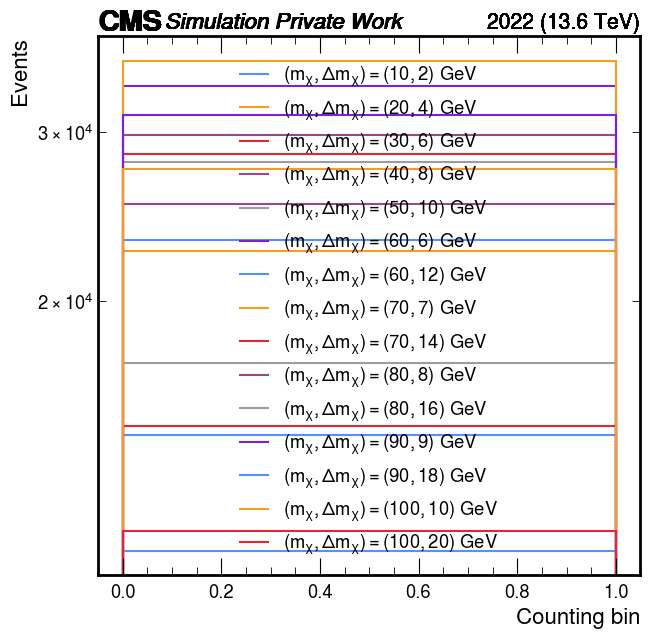

In [5]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'eff_num',
    'cut': selected_cut,
    'year': 2022
}
style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': None,     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': "Counting bin",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
}



if plot_dict["cut"] != den_cut:
    raise ValueError("Cuts differ. Use the same cut in both counting cells and rerun them.")

num_counts = {}
total_num = 0.0
num_cut = plot_dict["cut"]

# Reuse exactly the samples selected in the denominator cell.
for key in den_counts:
    m1, delta, ctau = key
    counts = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
    num = float(np.asarray(counts, dtype=float).sum())
    num_counts[key] = num
    total_num += num
    print(f"m1={m1}, delta={delta}, ctau={ctau}: numerator = {num:g}")

print(f"\nCut: {num_cut}")
print(f"Number of samples: {len(num_counts)}")
print(f"TOTAL numerator = {total_num:g}")
plt.show()

In [6]:
# Combine event counts before calculating efficiency.
if den_cut != num_cut:
    raise ValueError("Numerator and denominator cuts differ. Rerun both counting cells.")
if not den_counts or set(num_counts) != set(den_counts):
    raise ValueError("Sample lists must match and must not be empty.")

rows = []
for key, den in den_counts.items():
    num = num_counts[key]
    m1, delta, ctau = key
    if not np.all(np.isfinite([num, den])):
        raise ValueError(f"Non-finite counts for {key}.")
    if den < 0 or num < 0 or num > den:
        raise ValueError(f"Invalid numerator or denominator for {key}.")
    if not np.allclose([num, den], np.round([num, den])):
        raise ValueError("Binomial uncertainties require unit-weight event counts.")
    rows.append({
        "m1": m1, "delta": delta, "ctau": ctau,
        "numerator": num, "denominator": den,
        "efficiency (%)": 100 * num / den if den > 0 else np.nan,
    })

print(f"Cut: {den_cut}")
print(pd.DataFrame(rows).to_string(index=False))
total_num = sum(num_counts.values())
total_den = sum(den_counts.values())
print(f"\nTOTAL numerator   = {total_num:g}")
print(f"TOTAL denominator = {total_den:g}")

if total_den > 0:
    efficiency = total_num / total_den
    uncertainty = hist.intervals.ratio_uncertainty(
        np.array([total_num]), np.array([total_den]), "efficiency"
    )
    print(f"Combined efficiency = {total_num:g} / {total_den:g} = {efficiency:.6f}")
    print(f"Combined efficiency = {100 * efficiency:.3f}%")
    print(f"Uncertainty = -{100 * uncertainty[0, 0]:.3f}, "
          f"+{100 * uncertainty[1, 0]:.3f} percentage points")
else:
    print("Efficiency is undefined: total denominator is zero.")


Cut: cut2
 m1  delta  ctau  numerator  denominator  efficiency (%)
 10    0.2   100    14503.0     219982.0        6.592812
 20    0.2   100    22541.0     285981.0        7.881992
 30    0.2   100    28443.0     307204.0        9.258669
 40    0.2   100    29777.0     303385.0        9.814922
 50    0.2   100    27914.0     275148.0       10.145086
 60    0.1   100    33516.0     387820.0        8.642154
 60    0.2   100    23156.0     223856.0       10.344150
 70    0.1   100    35624.0     378359.0        9.415396
 70    0.2   100    14819.0     139727.0       10.605681
 80    0.1   100    25249.0     252285.0       10.008126
 80    0.2   100    17234.0     163058.0       10.569245
 90    0.1   100    31245.0     294517.0       10.608895
 90    0.2   100    10990.0     103316.0       10.637268
100    0.1   100    27467.0     249464.0       11.010406
100    0.2   100    11526.0     110862.0       10.396709

TOTAL numerator   = 354004
TOTAL denominator = 3.69496e+06
Combined efficienc

## Efficiency across all cut stages
Run the earlier cells first to define `sig_histo` and `samples`, then run these two cells. This section sums counts over the same selected samples at every available numbered cut. It reads histogram counts directly, without drawing counting plots.

Each efficiency uses that stage's denominator. For a fixed-reference efficiency comparison, check that the denominator is identical across stages. Independent good-vertex definitions can raise or lower efficiency; only cumulative selections imply a nonincreasing cutflow. Uncertainties assume unit-weight event counts, not general event weights. AA follows the numerator definition used when producing the Coffea file.


In [7]:
# Match the selected signal points to their stored histogram sample names.
sample_info = utils.get_signal_point_dict(sig_histo)
sample_names = []
for m1, deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            matches = sample_info[
                (sample_info.m1 == m1)
                & (sample_info.delta == delta)
                & (sample_info.ctau == ctau)
            ]
            if len(matches) != 1:
                raise ValueError(f"Expected one sample for {(m1, delta, ctau)}, found {len(matches)}.")
            sample_names.append(matches["name"].iloc[0])

if not sample_names:
    raise ValueError("No samples selected.")
if len(set(sample_names)) != len(sample_names):
    raise ValueError("The same sample was selected more than once.")

# Compare all numbered cuts found in either counting histogram.
den_cuts = set(sig_histo["eff_den"].axes["cut"])
num_cuts = set(sig_histo["eff_num"].axes["cut"])
cuts_to_plot = sorted(
    [c for c in den_cuts | num_cuts if c.startswith("cut") and c[3:].isdigit()],
    key=lambda c: int(c[3:]),
)
if not cuts_to_plot:
    raise ValueError("No numbered cut stages found.")

cutflow_rows = []
sample_cut_rows = []
for cut in cuts_to_plot:
    if cut not in den_cuts or cut not in num_cuts:
        raise ValueError(f"Numerator or denominator histogram is missing {cut}.")
    total_num = 0.0
    total_den = 0.0
    for sample in sample_names:
        num = float(sig_histo["eff_num"][{"samp": sample, "cut": cut}].values().sum())
        den = float(sig_histo["eff_den"][{"samp": sample, "cut": cut}].values().sum())
        if not np.all(np.isfinite([num, den])) or not 0 <= num <= den:
            raise ValueError(f"Invalid counts for {sample}, {cut}: {num} / {den}.")
        if not np.allclose([num, den], np.round([num, den])):
            raise ValueError("Expected unit-weight event counts.")
        sample_cut_rows.append({"cut": cut, "sample": sample, "numerator": num, "denominator": den})
        total_num += num
        total_den += den

    eff, unc_low, unc_high = np.nan, np.nan, np.nan
    if total_den > 0:
        eff = total_num / total_den
        unc = hist.intervals.ratio_uncertainty(
            np.array([total_num]), np.array([total_den]), "efficiency"
        )
        unc_low, unc_high = unc[0, 0], unc[1, 0]
    cutflow_rows.append({
        "cut": cut, "numerator": total_num, "denominator": total_den,
        "efficiency (%)": 100 * eff,
        "uncertainty low (pp)": 100 * unc_low,
        "uncertainty high (pp)": 100 * unc_high,
    })

cutflow_df = pd.DataFrame(cutflow_rows)
sample_cut_df = pd.DataFrame(sample_cut_rows)
print(f"Number of selected samples: {len(sample_names)}")
print("\nCombined counts and efficiency at each cut:")
print(cutflow_df.to_string(index=False))

# Check denominator consistency for each sample, not just the combined total.
den_table = sample_cut_df.pivot(index="sample", columns="cut", values="denominator")
changing_samples = den_table.index[den_table.nunique(axis=1) > 1].tolist()
if changing_samples:
    print("\nNOTE: Denominators change between stages for:")
    print("\n".join(changing_samples))
    print("Each efficiency above uses its own stage's denominator, not a fixed baseline.")
else:
    print("\nConfirmed: every selected sample has the same denominator at every cut.")

print("\nZero-denominator stages are undefined and omitted from the plotted points.")
# For a detailed per-sample check, run: print(sample_cut_df.to_string(index=False))


Number of selected samples: 15

Combined counts and efficiency at each cut:
  cut  numerator  denominator  efficiency (%)  uncertainty low (pp)  uncertainty high (pp)
 cut0   403200.0    3694964.0       10.912150              0.016223               0.016244
 cut1   373923.0    3694964.0       10.119801              0.015692               0.015714
 cut2   354004.0    3694964.0        9.580716              0.015314               0.015336
 cut3   353947.0    3694964.0        9.579173              0.015313               0.015335
 cut4   327893.0    3694964.0        8.874051              0.014796               0.014818
 cut5   319015.0    3694964.0        8.633778              0.014614               0.014636
 cut6   318861.0    3694964.0        8.629610              0.014610               0.014633
 cut7   316517.0    3694964.0        8.566173              0.014562               0.014584
 cut8   329622.0    3694964.0        8.920845              0.014831               0.014854
 cut9   329537

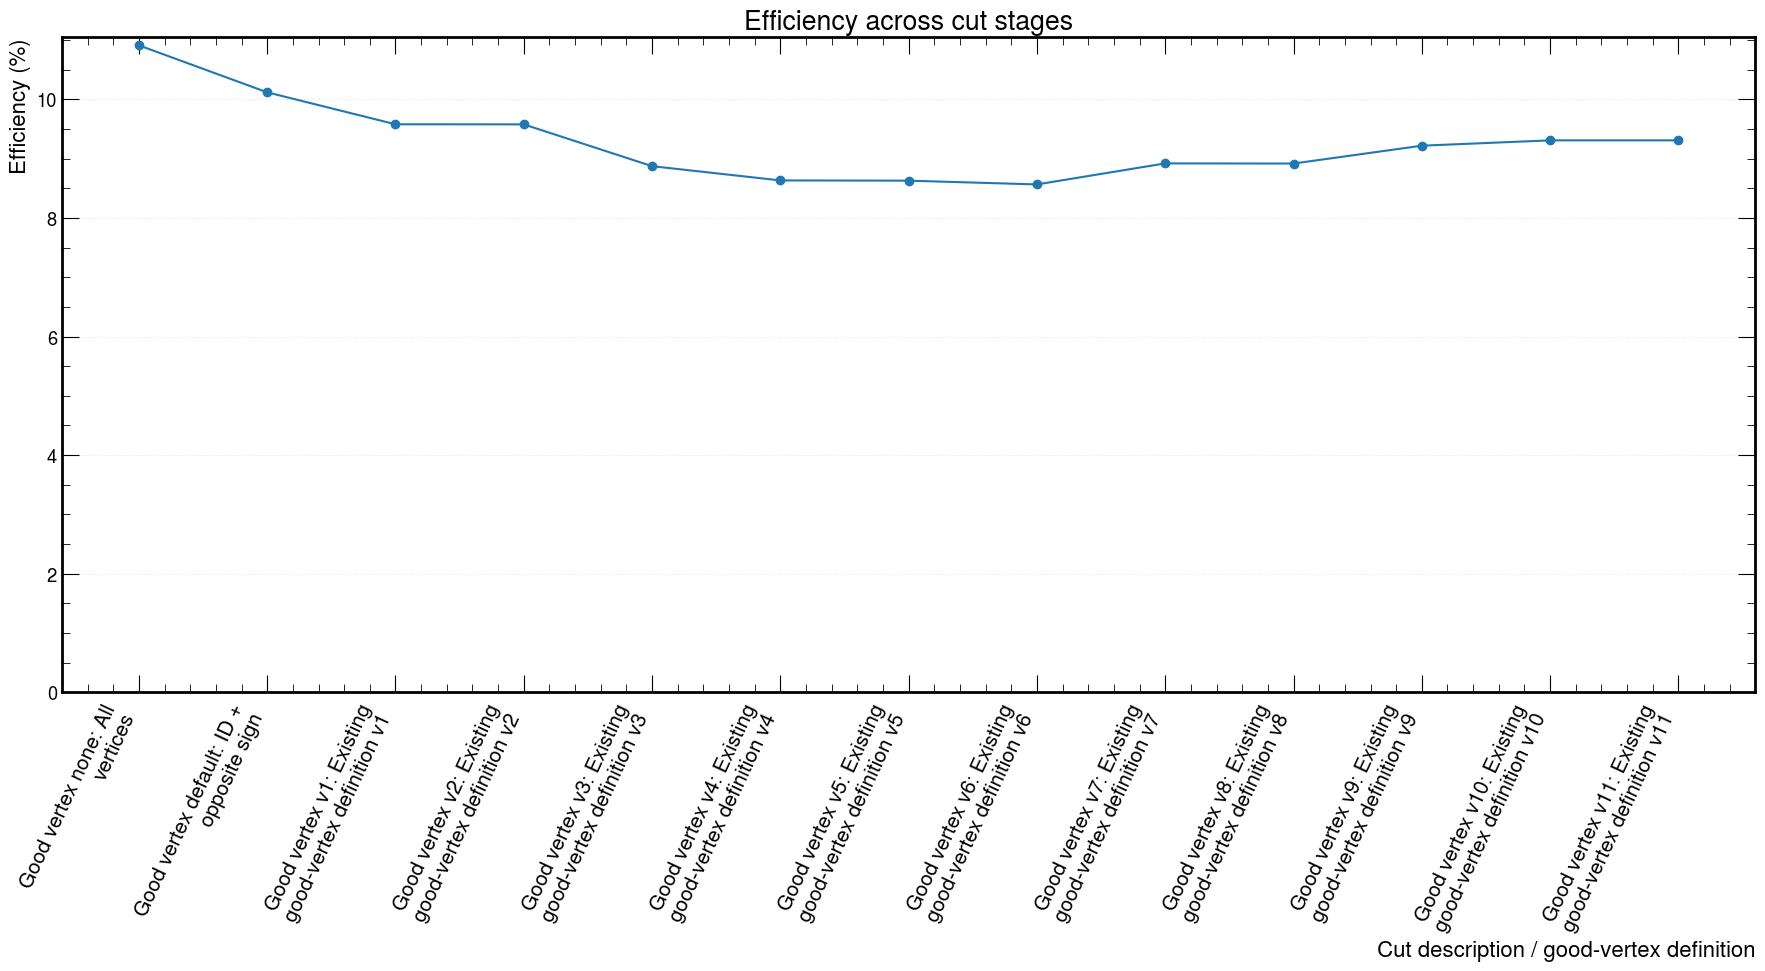

In [10]:
from textwrap import fill

cut_labels = [
    str(sig_histo["cutDesc"][cut]).split("@")[0].strip()
    for cut in cutflow_df["cut"]
]

x = np.arange(len(cutflow_df))
eff = cutflow_df["efficiency (%)"].to_numpy(dtype=float)
yerr = np.vstack([
    cutflow_df["uncertainty low (pp)"].to_numpy(dtype=float),
    cutflow_df["uncertainty high (pp)"].to_numpy(dtype=float),
])
valid = np.isfinite(eff) & np.all(np.isfinite(yerr), axis=0)
fig, ax = plt.subplots(figsize=(18, 10))
# NaN efficiencies break the connecting line at undefined stages.
ax.plot(x, eff, color="tab:blue", linewidth=1.5)
ax.errorbar(x[valid], eff[valid], yerr=yerr[:, valid],
            fmt="o", color="tab:blue", capsize=3)
ax.set_xticks(x)

ax.set_xticklabels(
    [fill(label, width=28) for label in cut_labels],
    rotation=65,
    ha="right",
    fontsize=15,
)

ax.set_xlabel("Cut description / good-vertex definition")
ax.set_ylabel("Efficiency (%)")
ax.set_title("Efficiency across cut stages")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
